
# SolarNL — Exploratieve Data-Analyse

## 1. Inleiding

In dit notebook wordt een exploratieve data-analyse (Exploratory Data Analysis, EDA) uitgevoerd op meetgegevens van zonnepanelen en omgevingscondities binnen het SolarNL-project.

De dataset bestaat uit twee onderdelen:

- **Weerdata:** metingen van omgevingsfactoren, waaronder temperatuur, relatieve luchtvochtigheid en luchtdruk.
- **Zonnepaneeldata:** elektrische en thermische metingen van acht afzonderlijke zonnepanelen.

### Doel van de analyse

Het doel van deze analyse is om inzicht te krijgen in de structuur, kwaliteit en eigenschappen van beide datasets. Daarnaast wordt onderzocht hoe omgevingsfactoren samenhangen met de elektrische prestaties van zonnepanelen.

De analyse bestaat uit de volgende stappen:

1. Inladen en structureren van de ruwe meetgegevens.
2. Splitsen van de weerdata en zonnepaneeldata.
3. Controleren van de datakwaliteit en ontbrekende meetwaarden.
4. Onderzoeken van de verdelingen en tijdsafhankelijke patronen.
5. Visualiseren van de belangrijkste meetvariabelen.
6. Onderzoeken van mogelijke verbanden tussen weersomstandigheden en zonnepaneelprestaties.

Voor de analyse wordt Python gebruikt, met bibliotheken zoals Pandas, NumPy, Matplotlib en Seaborn.



## 2. Data inladen en voorbereiden

De oorspronkelijke CSV-dataset is afkomstig uit InfluxDB en bevat meerdere meettabellen. Deze tabellen bevatten zowel weergegevens als metingen van verschillende zonnepanelen.

Om de gegevens overzichtelijk te kunnen analyseren, worden de volgende bewerkingen uitgevoerd:

1. Het CSV-bestand wordt ingelezen.
2. De afzonderlijke meettabellen worden herkend.
3. Overbodige metadata en lege kolommen worden verwijderd.
4. De meetgegevens worden opgesplitst in twee DataFrames:
   - `df_weather`: alle weergerelateerde metingen.
   - `df_solar`: alle metingen van de acht zonnepanelen.
5. Tijdstempels worden omgezet naar datetime-objecten en meetwaarden naar numerieke datatypes.
6. De gegevens worden chronologisch gesorteerd.

Hierdoor ontstaan twee afzonderlijke datasets die gebruikt worden voor de verdere exploratieve analyse.


In [1]:

import pandas as pd
import numpy as np
from io import StringIO
from IPython.display import display

# Bestandspad naar de oorspronkelijke CSV-dataset
bestandspad = "SolarNL_exploration_data.csv"

# CSV-bestand inlezen
with open(bestandspad, "r", encoding="utf-8-sig") as bestand:
    regels = bestand.readlines()

# Afzonderlijke InfluxDB-tabellen herkennen
tabellen = []
huidige_tabel = []

for regel in regels:

    if regel.startswith("#datatype"):
        if huidige_tabel:
            tabellen.append(huidige_tabel)
        huidige_tabel = []

    elif regel.startswith("#") or not regel.strip():
        continue

    else:
        huidige_tabel.append(regel)

if huidige_tabel:
    tabellen.append(huidige_tabel)

# Tabellen omzetten naar Pandas DataFrames
dataframes = []

for tabel in tabellen:

    df = pd.read_csv(
        StringIO("".join(tabel)),
        sep=";"
    )

    # Lege kolommen en overbodige metadata verwijderen
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

    df = df.drop(
        columns=["result", "table", "_start", "_stop"],
        errors="ignore"
    )

    # Volledig lege rijen verwijderen
    df = df.dropna(how="all")

    # Index opnieuw instellen
    df = df.reset_index(drop=True)

    dataframes.append(df)

# ============================================================
# WEERDATA SAMENVOEGEN
# ============================================================

df_weather = pd.concat(
    [
        df for df in dataframes
        if "Humidity-PVMET500" in df.columns
    ],
    ignore_index=True
)

# ============================================================
# ZONNEPANEELDATA SAMENVOEGEN
# ============================================================

# Ook tabellen met uitsluitend Pt100-metingen meenemen
solar_meetkolommen = [
    "ff", "impp", "isc", "vmpp", "voc"
]

solar_tabellen = [
    df for df in dataframes
    if (
        any(kolom in df.columns for kolom in solar_meetkolommen)
        or any(kolom.startswith("Pt100") for kolom in df.columns)
    )
    and (
        "pvdeviceId" in df.columns
        or "label" in df.columns
    )
]

df_solar = pd.concat(
    solar_tabellen,
    ignore_index=True
)

# ============================================================
# TIJDSTEMPELS EN MEETWAARDEN CONVERTEREN
# ============================================================

for df in [df_weather, df_solar]:

    df["_time"] = pd.to_datetime(
        df["_time"],
        utc=True,
        errors="coerce"
    )

    # Kolommen die geen numerieke meetwaarden bevatten
    metadata_kolommen = [
        "_time", "_measurement", "label", "pvdeviceId"
    ]

    for kolom in df.columns:
        if kolom not in metadata_kolommen:
            df[kolom] = pd.to_numeric(
                df[kolom],
                errors="coerce"
            )

    # Metingen chronologisch sorteren
    df.sort_values("_time", inplace=True)
    df.reset_index(drop=True, inplace=True)

# ============================================================
# OORSPRONKELIJKE ZONNEPANEELDATA BEWAREN
# ============================================================

# Deze kopie blijft beschikbaar voor latere bewerkingen
df_solar_raw = df_solar.copy()

# ============================================================
# CONTROLE
# ============================================================

print("Datasets succesvol ingeladen!")
print(f"Weerdataset:         {df_weather.shape}")
print(f"Zonnepaneeldataset:  {df_solar.shape}")

print(f"\nAantal InfluxDB-tabellen: {len(dataframes)}")
print(f"Zonnepaneeltabellen:       {len(solar_tabellen)}")


Datasets succesvol ingeladen!
Weerdataset:         (5579, 7)
Zonnepaneeldataset:  (44632, 19)

Aantal InfluxDB-tabellen: 10
Zonnepaneeltabellen:       8



### 2.1 Opschonen van de zonnepaneeldata

De zonnepaneeldata bevat metingen met verschillende meetfrequenties.

De variabelen `CMP-10` en `Ref` worden iedere minuut geregistreerd. De Pt100-temperatuurmetingen en elektrische karakteristieken (`ff`, `impp`, `isc`, `vmpp` en `voc`) worden iedere tien minuten geregistreerd.

Omdat de analyse zich richt op de elektrische prestaties van de zonnepanelen, worden alleen de meetmomenten behouden waarop deze volledige metingen beschikbaar zijn. alle rijen zonder meetwaarden zullen we verwijderen.

Daarnaast heeft ieder zonnepaneel een eigen Pt100-temperatuursensor. Deze afzonderlijke temperatuurkolommen worden samengevoegd tot één kolom genaamd `Pt100`, waarbij de bijbehorende temperatuur per zonnepaneel behouden blijft.

De weerdata blijft ongewijzigd, zodat alle oorspronkelijke omgevingsmetingen beschikbaar blijven voor verdere analyse.


Opschonen zonnepaneeldata voltooid!
Metingen vóór opschonen: 44632
Metingen na opschonen:   4456
Verwijderde metingen:    40176


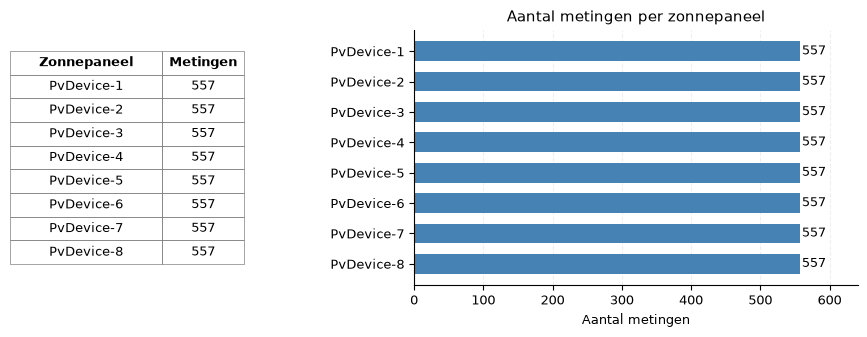


Beschikbare metingen per variabele en zonnepaneel:


,Pt100,ff,impp,isc,vmpp,voc
label,,,,,,
PvDevice-1,556,209,209,209,209,209
PvDevice-2,556,218,218,218,218,218
PvDevice-3,556,174,174,174,174,174
PvDevice-4,556,174,174,174,174,174
PvDevice-5,556,174,174,174,174,174
PvDevice-6,556,174,174,174,174,174
PvDevice-7,556,54,54,54,54,54
PvDevice-8,556,54,54,54,54,54



Eerste 10 rijen opgeschoonde zonnepaneeldata:


,_time,_measurement,label,pvdeviceId,CMP-10,Ref,ff,impp,isc,vmpp,voc,Pt100
0,2026-10-23 13:50:00+00:00,pvblocksmeasurement,PvDevice-1,2.0,236.848073,285557.0,79.55,0.35965,0.38859,39.619,46.092,12.099
1,2026-10-23 13:50:00+00:00,pvblocksmeasurement,PvDevice-2,3.0,236.848073,285557.0,82.69,0.36081,0.37968,39.503,45.398,15.218
2,2026-10-23 13:50:00+00:00,pvblocksmeasurement,PvDevice-3,4.0,236.848073,285557.0,29.39,0.36081,1.06836,39.503,45.398,15.780
3,2026-10-23 13:50:00+00:00,pvblocksmeasurement,PvDevice-4,5.0,236.848073,285557.0,32.58,0.36081,0.96374,39.503,45.398,13.174
4,2026-10-23 13:50:00+00:00,pvblocksmeasurement,PvDevice-5,6.0,236.848073,285557.0,32.58,0.36081,0.96374,39.503,45.398,12.756
5,2026-10-23 13:50:00+00:00,pvblocksmeasurement,PvDevice-6,7.0,236.848073,285557.0,32.58,0.36081,0.96374,39.503,45.398,12.743
6,2026-10-23 13:50:00+00:00,pvblocksmeasurement,PvDevice-7,8.0,236.848073,285557.0,80.09,0.36081,0.39203,39.503,45.398,9.603
7,2026-10-23 13:50:00+00:00,pvblocksmeasurement,PvDevice-8,9.0,236.848073,285557.0,81.21,0.36081,0.38661,39.503,45.398,-6.968
8,2026-10-23 14:00:00+00:00,pvblocksmeasurement,PvDevice-1,2.0,232.879819,285562.0,80.22,0.25722,0.27903,38.989,44.803,11.831
9,2026-10-23 14:00:00+00:00,pvblocksmeasurement,PvDevice-2,3.0,232.879819,285562.0,82.12,0.25747,0.27246,38.932,44.803,15.073


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ============================================================
# 1. ZONNEPANEELDATA OPSCHONEN
# ============================================================

# Begin opnieuw met de oorspronkelijke data,
# zodat eerder verwijderde meetwaarden terugkomen
df_solar = df_solar_raw.copy()

# Oorspronkelijk aantal zonnepaneelmetingen
aantal_voor = len(df_solar)

# Alleen de oorspronkelijke Pt100-sensorkolommen herkennen
# De samengevoegde kolom 'Pt100' wordt uitgesloten
pt100_kolommen = [
    kolom for kolom in df_solar.columns
    if kolom.startswith("Pt100") and kolom != "Pt100"
]

# Pt100-sensorkolommen samenvoegen indien aanwezig
if pt100_kolommen:

    pt100_samengevoegd = (
        df_solar[pt100_kolommen]
        .bfill(axis=1)
        .iloc[:, 0]
    )

    # Eventueel bestaande Pt100-waarden behouden
    if "Pt100" in df_solar.columns:
        df_solar["Pt100"] = (
            df_solar["Pt100"]
            .combine_first(pt100_samengevoegd)
        )
    else:
        df_solar["Pt100"] = pt100_samengevoegd

    # Oorspronkelijke sensorkolommen verwijderen
    df_solar = df_solar.drop(columns=pt100_kolommen)

# Meetvariabelen
meetkolommen = [
    "Pt100",
    "ff",
    "impp",
    "isc",
    "vmpp",
    "voc"
]

# Meetwaarden omzetten naar numerieke waarden
for kolom in meetkolommen:
    df_solar[kolom] = pd.to_numeric(
        df_solar[kolom],
        errors="coerce"
    )

# Alleen meetrijen verwijderen waarbij
# ALLE zes meetvariabelen ontbreken
df_solar = df_solar.dropna(
    subset=meetkolommen,
    how="all"
).copy()

# Rijen zonder tijdstip of paneelidentificatie verwijderen
df_solar = df_solar.dropna(
    subset=["_time", "label"]
).copy()

# Chronologisch sorteren en index herstellen
df_solar = df_solar.sort_values(
    ["_time", "pvdeviceId"]
).reset_index(drop=True)

# Resultaten controleren
aantal_na = len(df_solar)

print("Opschonen zonnepaneeldata voltooid!")
print(f"Metingen vóór opschonen: {aantal_voor}")
print(f"Metingen na opschonen:   {aantal_na}")
print(f"Verwijderde metingen:    {aantal_voor - aantal_na}")


# ============================================================
# 2. AANTAL MEETRIJEN PER ZONNEPANEEL
# ============================================================

# Aantal behouden meetrijen per zonnepaneel berekenen
metingen_per_paneel = (
    df_solar.groupby("label")
    .size()
    .to_frame("Aantal metingen")
)

# Figuur met tabel links en grafiek rechts
fig, (ax_tabel, ax_grafiek) = plt.subplots(
    1, 2,
    figsize=(9, 3.5),
    gridspec_kw={"width_ratios": [1.2, 2.5]}
)

# Transparante achtergrond
fig.patch.set_facecolor("none")
ax_tabel.set_facecolor("none")
ax_grafiek.set_facecolor("none")


# -----------------------------
# Links: tabel
# -----------------------------

ax_tabel.axis("off")

tabel = ax_tabel.table(
    cellText=[
        [paneel, aantal]
        for paneel, aantal in zip(
            metingen_per_paneel.index,
            metingen_per_paneel["Aantal metingen"]
        )
    ],
    colLabels=["Zonnepaneel", "Metingen"],
    colWidths=[0.65, 0.35],
    cellLoc="center",
    loc="center"
)

tabel.auto_set_font_size(False)
tabel.set_fontsize(9)
tabel.scale(1.1, 1.5)

# Tabelcellen transparant maken
for (rij, kolom), cel in tabel.get_celld().items():

    cel.set_facecolor("none")
    cel.set_edgecolor("gray")
    cel.set_linewidth(0.5)

    if rij == 0:
        cel.set_text_props(weight="bold")


# -----------------------------
# Rechts: staafdiagram
# -----------------------------

ax_grafiek.barh(
    metingen_per_paneel.index,
    metingen_per_paneel["Aantal metingen"],
    color="steelblue",
    height=0.65
)

ax_grafiek.invert_yaxis()

ax_grafiek.set_title(
    "Aantal metingen per zonnepaneel",
    fontsize=11
)

ax_grafiek.set_xlabel(
    "Aantal metingen",
    fontsize=9
)

ax_grafiek.tick_params(
    axis="both",
    labelsize=9
)

ax_grafiek.grid(
    axis="x",
    linestyle="--",
    alpha=0.2
)

ax_grafiek.set_axisbelow(True)

# Meetwaarden naast de staven
for i, aantal in enumerate(
    metingen_per_paneel["Aantal metingen"]
):
    ax_grafiek.text(
        aantal + 3,
        i,
        str(aantal),
        va="center",
        fontsize=9
    )

ax_grafiek.set_xlim(
    0,
    metingen_per_paneel["Aantal metingen"].max() * 1.15
)

# Onnodige randen verwijderen
ax_grafiek.spines["top"].set_visible(False)
ax_grafiek.spines["right"].set_visible(False)

# Indeling
fig.subplots_adjust(
    left=0.04,
    right=0.97,
    top=0.88,
    bottom=0.15,
    wspace=0.55
)

plt.show()


# ============================================================
# 3. BESCHIKBARE METINGEN PER VARIABELE
# ============================================================

print("\nBeschikbare metingen per variabele en zonnepaneel:")

beschikbare_metingen = (
    df_solar.groupby("label")[meetkolommen]
    .count()
)

display(beschikbare_metingen)


# ============================================================
# 4. EERSTE TIEN RIJEN CONTROLEREN
# ============================================================

print("\nEerste 10 rijen opgeschoonde zonnepaneeldata:")
display(df_solar.head(10))



### Analyse van de opgeschoonde zonnepaneeldata

Na het inladen en verwerken van de oorspronkelijke zonnepaneeldata is een dataset samengesteld waarin de meetwaarden van de acht zonnepanelen overzichtelijk zijn opgeslagen.

De oorspronkelijke dataset bevatte **44.632 meetrijen**. Na het opschonen blijven **4.456 meetrijen** over. Dit betekent dat 40.176 rijen (ongeveer 90%) zijn verwijderd.

Dit grote verschil wordt veroorzaakt doordat de oorspronkelijke InfluxDB-export veel rijen bevat waarin geen van de zes geselecteerde meetvariabelen (`Pt100`, `ff`, `impp`, `isc`, `vmpp` en `voc`) beschikbaar is.

Bij de opschoning zijn uitsluitend rijen verwijderd waarin alle zes meetvariabelen ontbreken. Rijen met minimaal één geldige meetwaarde zijn behouden. Hierdoor blijven bijvoorbeeld temperatuurmetingen beschikbaar wanneer op hetzelfde tijdstip geen elektrische metingen zijn geregistreerd.

### Beschikbaarheid van de meetvariabelen

Uit het overzicht van de beschikbare meetwaarden blijkt dat de temperatuurmetingen aanzienlijk vollediger zijn dan de elektrische metingen.

- **Paneeltemperatuur (Pt100):** voor ieder zonnepaneel zijn 556 temperatuurmetingen beschikbaar. De temperatuurmetingen vormen daarmee de meest complete meetreeks.
- **PV1 en PV2:** beschikken over respectievelijk 209 en 218 elektrische metingen per variabele.
- **PV3–PV6:** beschikken ieder over 174 elektrische metingen per variabele.
- **PV7 en PV8:** beschikken ieder over slechts 54 elektrische metingen per variabele.

Opvallend is dat de vijf elektrische variabelen (`ff`, `impp`, `isc`, `vmpp` en `voc`) per zonnepaneel steeds hetzelfde aantal beschikbare metingen hebben. Dit suggereert dat deze variabelen gezamenlijk worden geregistreerd of beschikbaar komen.

De temperatuurmetingen worden daarentegen op veel meer tijdstippen geregistreerd. Hierdoor kunnen temperatuurreeksen over vrijwel de gehele meetperiode worden geanalyseerd, terwijl de elektrische analyses op een beperktere hoeveelheid meetgegevens zijn gebaseerd.

### Structuur van de opgeschoonde dataset

De eerste tien rijen laten zien dat de gegevens chronologisch zijn geordend en dat ieder zonnepaneel afzonderlijk herkenbaar is aan het label en de bijbehorende `pvdeviceId`.

De meetgegevens bevatten naast de zes onderzochte variabelen ook de kolommen `CMP-10` en `Ref`. Deze kunnen mogelijk worden gebruikt voor aanvullende analyses, bijvoorbeeld in combinatie met instralingsmetingen, mits de betekenis en eenheden van deze kolommen bekend zijn.

Ook valt op dat sommige elektrische meetwaarden van verschillende zonnepanelen exact overeenkomen, terwijl de temperatuurmetingen verschillen. Dit kan samenhangen met de manier waarop de elektrische meetgegevens worden geregistreerd of aan de zonnepanelen worden gekoppeld.

### Samenvatting

De opschoning heeft geresulteerd in een dataset van 4.456 meetrijen, waarbij zoveel mogelijk beschikbare meetwaarden behouden zijn.

De temperatuurmetingen zijn voor alle acht zonnepanelen vrijwel volledig beschikbaar. De elektrische meetwaarden zijn minder compleet en verschillen aanzienlijk in aantal tussen de zonnepanelen.

Deze verschillen in databeschikbaarheid zijn belangrijk voor de exploratieve analyse in hoofdstuk 3. Vooral bij vergelijkingen tussen zonnepanelen moet rekening worden gehouden met het feit dat niet alle variabelen op dezelfde tijdstippen beschikbaar zijn.

De opgeschoonde dataset vormt hiermee een geschikte basis voor het visualiseren van temperatuurverlopen, elektrische karakteristieken en mogelijke patronen in de zonnepaneelmetingen.



## 3. Exploratieve analyse en visualisaties

In dit hoofdstuk worden de zonnepaneelmetingen onderzocht aan de hand van beschrijvende statistiek en visualisaties.

Het doel is om inzicht te krijgen in de beschikbare meetgegevens, verschillen tussen de acht zonnepanelen te identificeren en mogelijke patronen en afwijkingen te herkennen.

### 3.1 Meetoverzicht per zonnepaneel

Als eerste wordt een overzicht gemaakt van de beschikbare metingen per zonnepaneel.

Hierbij worden de volgende gegevens weergegeven:

- Het aantal beschikbare metingen.
- Het eerste en laatste geregistreerde meetmoment.
- Het mediane tijdsinterval tussen opeenvolgende metingen.

Dit overzicht geeft inzicht in de omvang en de tijdsdekking van de dataset. De verdeling van de meetwaarden, inclusief minimum, maximum en spreiding, wordt in de volgende paragraaf grafisch onderzocht.



In [3]:

# Meetgegevens chronologisch sorteren
df_overzicht = df_solar.sort_values(
    ["label", "_time"]
).copy()

# Tijdsverschil tussen opeenvolgende metingen berekenen
df_overzicht["Tijdsverschil"] = (
    df_overzicht.groupby("label")["_time"].diff()
)

# Overzicht per zonnepaneel
tabel_tijd = df_overzicht.groupby("label").agg(
    Aantal_metingen=("_time", "size"),
    Eerste_meting=("_time", "min"),
    Laatste_meting=("_time", "max"),
    Mediaan_interval=("Tijdsverschil", "median")
)

# Mediaan interval omzetten naar minuten
tabel_tijd["Mediaan_interval"] = (
    tabel_tijd["Mediaan_interval"]
    .dt.total_seconds()
    .div(60)
    .round(1)
)

# Kolomnamen aanpassen
tabel_tijd.columns = [
    "Aantal metingen",
    "Eerste meting",
    "Laatste meting",
    "Interval (min)"
]

# Datums leesbaar maken
for kolom in ["Eerste meting", "Laatste meting"]:
    tabel_tijd[kolom] = (
        tabel_tijd[kolom]
        .dt.strftime("%d-%m-%Y %H:%M")
    )

# Tabel tonen
display(tabel_tijd)


,Aantal metingen,Eerste meting,Laatste meting,Interval (min)
label,,,,
PvDevice-1,557,23-10-2026 13:50,27-10-2026 10:50,10.0
PvDevice-2,557,23-10-2026 13:50,27-10-2026 10:50,10.0
PvDevice-3,557,23-10-2026 13:50,27-10-2026 10:50,10.0
PvDevice-4,557,23-10-2026 13:50,27-10-2026 10:50,10.0
PvDevice-5,557,23-10-2026 13:50,27-10-2026 10:50,10.0
PvDevice-6,557,23-10-2026 13:50,27-10-2026 10:50,10.0
PvDevice-7,557,23-10-2026 13:50,27-10-2026 10:50,10.0
PvDevice-8,557,23-10-2026 13:50,27-10-2026 10:50,10.0



### 3.2 Boxplotmatrix van de zonnepaneelmetingen

Om de meetwaarden van de acht zonnepanelen te vergelijken, wordt een matrix van zes boxplots opgesteld.

De volgende variabelen worden onderzocht:

- **Pt100:** paneeltemperatuur (°C).
- **ff:** fill factor.
- **impp:** stroom bij maximaal vermogen (A).
- **isc:** kortsluitstroom (A).
- **vmpp:** spanning bij maximaal vermogen (V).
- **voc:** openklemspanning (V).

Iedere boxplot toont de mediaan, de interkwartielafstand (IQR), de spreiding en mogelijke uitschieters.

Hiermee kunnen verschillen in meetwaarden tussen zonnepanelen worden geïdentificeerd en opvallende metingen worden geselecteerd voor verdere analyse.


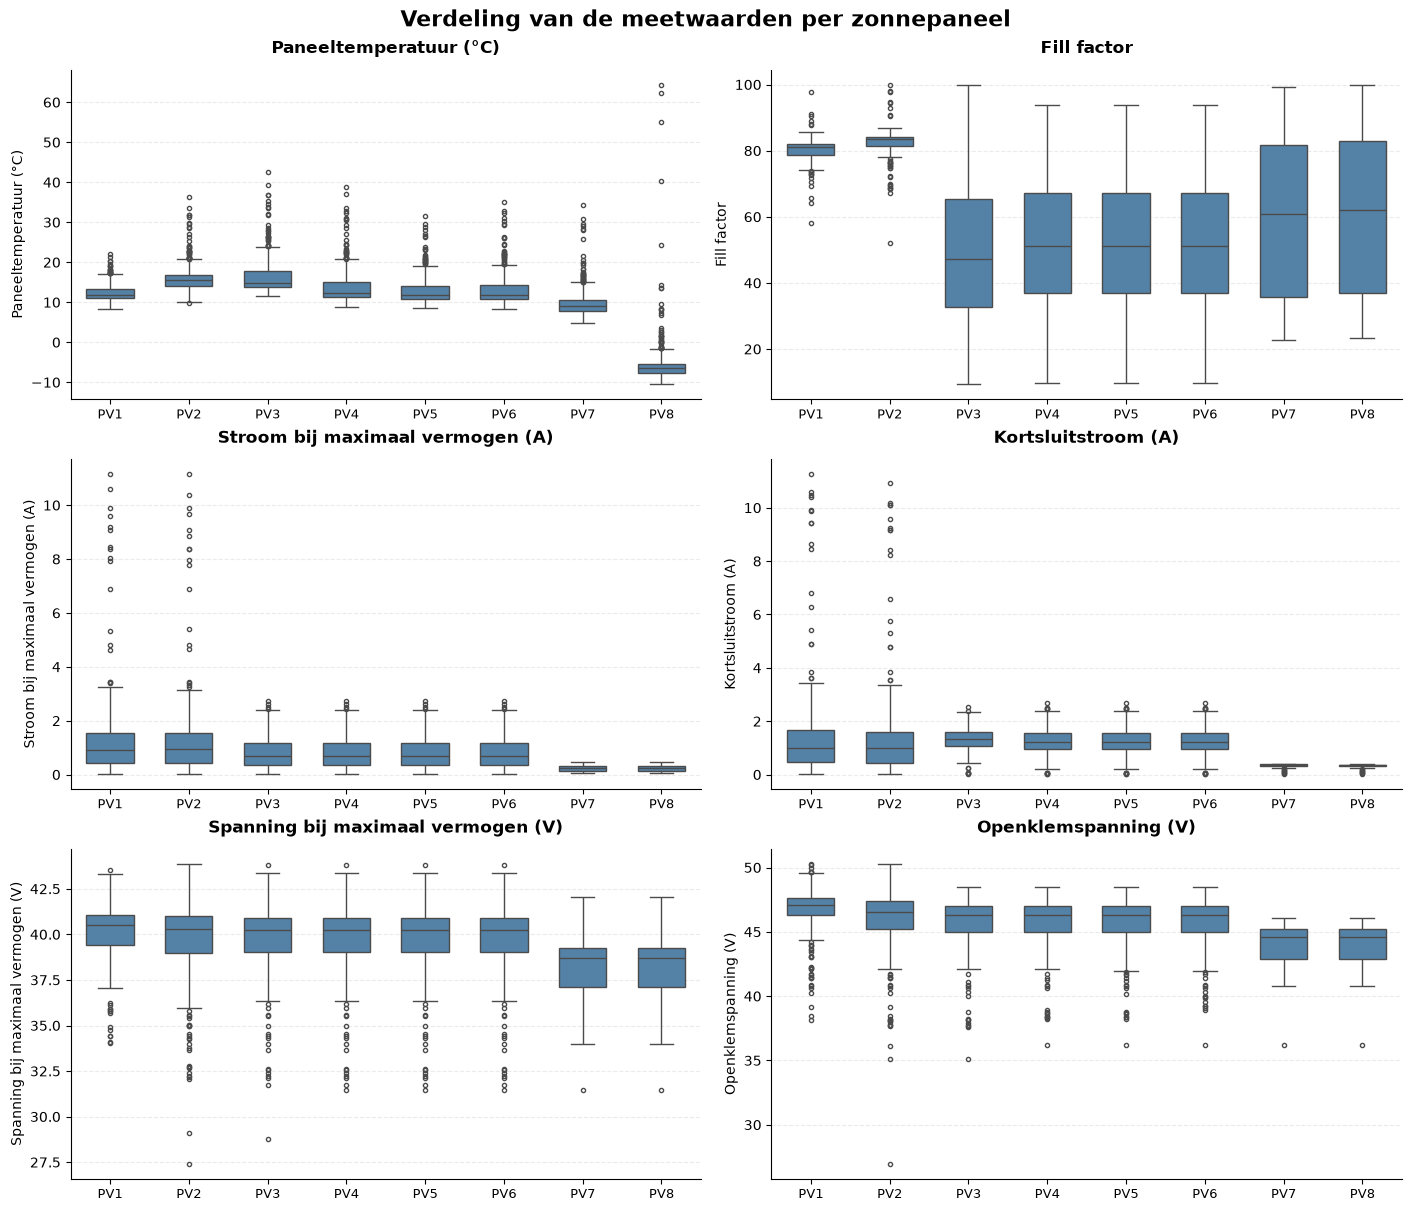

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# Meetvariabelen en grafiektitels
variabelen = {
    "Pt100": "Paneeltemperatuur (°C)",
    "ff": "Fill factor",
    "impp": "Stroom bij maximaal vermogen (A)",
    "isc": "Kortsluitstroom (A)",
    "vmpp": "Spanning bij maximaal vermogen (V)",
    "voc": "Openklemspanning (V)"
}

# Zonnepanelen op nummer sorteren
panelen = sorted(
    df_solar["label"].dropna().unique(),
    key=lambda naam: int(naam.split("-")[-1])
)

# Matrix met 3 rijen en 2 kolommen
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14, 12),
    constrained_layout=True
)

# Kleuren
kleur = "#4682B4"

# Iedere meetvariabele plotten
for ax, (kolom, titel) in zip(
    axes.flat,
    variabelen.items()
):

    sns.boxplot(
        data=df_solar,
        x="label",
        y=kolom,
        order=panelen,
        ax=ax,
        color=kleur,
        width=0.6,
        linewidth=1,
        fliersize=3
    )

    # Grafiekopmaak
    ax.set_title(
        titel,
        fontsize=12,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("")
    ax.set_ylabel(titel, fontsize=10)

    # Kortere labels: PvDevice-1 -> PV1
    ax.set_xticks(range(len(panelen)))
    ax.set_xticklabels(
        [f"PV{i+1}" for i in range(len(panelen))],
        fontsize=9
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    sns.despine(ax=ax)

# Algemene titel
fig.suptitle(
    "Verdeling van de meetwaarden per zonnepaneel",
    fontsize=16,
    fontweight="bold"
)

plt.show()


### 1. Paneeltemperatuur (Pt100)

In de eerste grafiek zien we duidelijke temperatuurverschillen tussen de zonnepanelen.

- **PV1:** relatief stabiele temperatuur, met een mediaan rond 13–14 °C.
- **PV2 en PV3:** hogere mediane temperaturen, rond 17–19 °C.
- **PV4–PV6:** vergelijkbare temperaturen, met medianen rond 14–16 °C.
- **PV7:** lagere temperaturen, rond 9 °C.
- **PV8:** uitsluitend negatieve temperaturen, rond −7 °C.

Vooral PV8 is opvallend. Het temperatuurverschil met de overige panelen is aanzienlijk. Dit biedt een interessante mogelijkheid om de betrouwbaarheid van temperatuurmetingen te onderzoeken, bijvoorbeeld door sensorwaarden te vergelijken met de omgevingstemperatuur of door de meetopstelling en sensorkalibratie te bestuderen.

### 2. Fill factor (ff)

De fill factor beschrijft de verhouding tussen het maximale elektrische vermogen en het product van de openklemspanning en kortsluitstroom.

In de grafiek zien we twee duidelijke groepen:

- **PV1 en PV2:** relatief hoge en stabiele fill factor, met medianen rond 80–83.
- **PV3–PV6:** lagere medianen, rond 47–52, met een aanzienlijk grotere spreiding.
- **PV7 en PV8:** medianen rond 60, eveneens met een grote spreiding.

De schaal suggereert dat de fill factor als percentage wordt weergegeven. Informatie over de definitie en berekeningswijze van `ff` zou nuttig zijn om deze waarden correct te interpreteren.

Het verschil tussen PV1–PV2 en de overige zonnepanelen kan wijzen op verschillen in elektrische prestaties, meetomstandigheden of paneelconfiguratie. Een mogelijke onderzoekstoepassing is het vergelijken van de fill factor met temperatuur, zoninstraling en andere elektrische eigenschappen om deze verschillen beter te begrijpen.

### 3. Stroom bij maximaal vermogen (impp)

Bij de stroommetingen zien we:

- **PV1 en PV2:** de grootste spreiding en uitschieters tot ongeveer 11 A.
- **PV3–PV6:** onderling vergelijkbare verdelingen, met de meeste waarden onder ongeveer 2,5 A.
- **PV7 en PV8:** duidelijk lagere stroomwaarden.

De hoge uitschieters van PV1 en PV2 zijn interessant. De dataset biedt mogelijkheden om deze stroommetingen te vergelijken met de beschikbare zoninstralingsgegevens. Hiermee kan bijvoorbeeld worden onderzocht hoe de stroomopwekking verandert bij verschillende instralingsniveaus.

Ook kan een vergelijking met de technische specificaties van de zonnepanelen helpen om verschillen in stroomsterkte te verklaren.

### 4. Kortsluitstroom (isc)

De kortsluitstroom vertoont een vergelijkbaar patroon als `impp`.

PV1 en PV2 hebben opnieuw een grotere spreiding en opvallend hoge uitschieters. PV3–PV6 hebben compactere verdelingen, terwijl PV7 en PV8 relatief lage waarden laten zien.

Dit is interessant omdat de kortsluitstroom sterk samenhangt met de hoeveelheid invallende zoninstraling.

Een mogelijke onderzoekstoepassing is het combineren van de kortsluitstroom met de instralingsmetingen van de beschikbare sensoren. Hiermee kan de relatie tussen zoninstraling en kortsluitstroom worden gevisualiseerd en kunnen verschillen tussen zonnepanelen worden bestudeerd.

### 5. Spanning bij maximaal vermogen (vmpp)

Bij de spanning zien we juist een relatief consistent beeld:

- **PV1–PV6:** medianen rond 40 V.
- **PV7 en PV8:** lagere medianen, rond 38–39 V.
- **Alle panelen:** enkele lage uitschieters.

De relatief beperkte verschillen in spanning, tegenover de grotere verschillen in stroom, suggereren dat de stroommetingen een belangrijke rol kunnen spelen bij verschillen in elektrisch vermogen.

Een interessante toepassing van de dataset is het berekenen van het maximale elektrische vermogen met behulp van `impp` en `vmpp`. Hiermee kunnen vermogenscurves worden opgesteld en kunnen de elektrische prestaties van de zonnepanelen onder verschillende omstandigheden worden vergeleken.

### 6. Openklemspanning (voc)

Ook bij de openklemspanning zien we duidelijke overeenkomsten:

- **PV1–PV6:** medianen rond 46–47 V.
- **PV7 en PV8:** iets lagere medianen, rond 44–45 V.
- **Vooral PV1–PV6:** verschillende lage uitschieters.

De spanning is dus relatief stabiel ten opzichte van de stroom, maar er zijn wel verschillen tussen de panelen.

De openklemspanning is interessant voor onderzoek naar de temperatuurafhankelijkheid van zonnepanelen. Door `voc` te combineren met de paneeltemperatuur (`Pt100`) kan bijvoorbeeld worden onderzocht hoe de spanning verandert bij verschillende temperaturen.

Aanvullende informatie over de temperatuurcoëfficiënten en technische specificaties van de zonnepanelen zou hierbij waardevol zijn.

---

## Belangrijkste bevindingen

| Observatie | Betrokken panelen | Mogelijke onderzoekstoepassing |
|---|---|---|
| Hoge en stabiele fill factor | PV1–PV2 | Relatie tussen fill factor, temperatuur en elektrische eigenschappen |
| Grote stroomuitschieters | PV1–PV2 | Invloed van zoninstraling op de opgewekte stroom |
| Vergelijkbare elektrische verdelingen | PV3–PV6 | Onderlinge vergelijking van elektrische prestaties |
| Lage stroom en spanning | PV7–PV8 | Invloed van paneeltype, configuratie en meetomstandigheden |
| Opvallend negatieve temperatuur | PV8 | Betrouwbaarheid van sensoren en temperatuurmetingen |
| Relatief stabiele spanningswaarden | PV1–PV6 | Temperatuurafhankelijkheid van de paneelspanning |


### Samenvatting

De boxplotmatrix laat duidelijke verschillen zien tussen de acht zonnepanelen. Vooral de hoge stroomuitschieters bij PV1 en PV2, de verschillen in fill factor en de afwijkende temperatuurmetingen bij PV8 zijn opvallende kenmerken van de dataset.

De zonnepanelen zijn grotendeels gedurende dezelfde periode geregistreerd en hebben allemaal een mediaan meetinterval van 10 minuten. Het aantal beschikbare volledige metingen verschilt echter aanzienlijk per zonnepaneel.

Hierdoor kunnen de verdelingen gebaseerd zijn op verschillende meetmomenten en omstandigheden. Daarnaast kunnen verschillen in paneeltype, configuratie en omgevingsomstandigheden een rol spelen.

De dataset biedt interessante mogelijkheden voor natuurkundig onderzoek, waaronder de relatie tussen zoninstraling en stroomopwekking, de temperatuurafhankelijkheid van de spanning en het vergelijken van elektrische karakteristieken.

Aanvullende gegevens over de technische specificaties, paneelopstelling en sensorkalibratie zouden waardevol zijn om verdergaande uitspraken te kunnen doen over de prestaties en eigenschappen van de zonnepanelen.




### 3.3 Tijdreeksen van de zonnepaneelmetingen

Naast de verdeling van de meetwaarden is ook het verloop in de tijd interessant. Daarom worden de zes meetvariabelen uitgezet tegen de tijd.

De tijdreeksen geven inzicht in:

- De veranderingen in paneeltemperatuur gedurende de meetperiode.
- De variatie in de fill factor en elektrische meetwaarden.
- De overeenkomsten en verschillen tussen zonnepanelen.
- De aanwezigheid van uitschieters, onderbrekingen en terugkerende patronen.

De grafieken geven een overzicht van het tijdsafhankelijke gedrag van de zonnepanelen en illustreren welke natuurkundige relaties met deze dataset onderzocht zouden kunnen worden.


In [9]:

import pandas as pd
import plotly.graph_objects as go

# Meetvariabelen en bijbehorende titels
variabelen = {
    "Pt100": ("Paneeltemperatuur", "Temperatuur (°C)"),
    "ff": ("Fill factor", "Fill factor"),
    "impp": ("Stroom bij maximaal vermogen", "Stroom (A)"),
    "isc": ("Kortsluitstroom", "Stroom (A)"),
    "vmpp": ("Spanning bij maximaal vermogen", "Spanning (V)"),
    "voc": ("Openklemspanning", "Spanning (V)"),
    "CMP-10": ("CMP-10 metingen", "CMP-10 (eenheid onbekend)")
}

# Vaste kleuren per zonnepaneel
paneelkleuren = {
    "PvDevice-1": "#1565C0",
    "PvDevice-2": "#42A5F5",
    "PvDevice-3": "#2E7D32",
    "PvDevice-4": "#66BB6A",
    "PvDevice-5": "#00897B",
    "PvDevice-6": "#80CBC4",
    "PvDevice-7": "#E65100",
    "PvDevice-8": "#8E24AA"
}

# Data voorbereiden
df_tijd = df_solar.copy()

df_tijd["_time"] = pd.to_datetime(
    df_tijd["_time"], utc=True
)

# Panelen sorteren
panelen = sorted(
    df_tijd["label"].dropna().unique(),
    key=lambda naam: int(naam.split("-")[-1])
)

# Voor iedere variabele een onafhankelijke figuur
for variabele, (titel, eenheid) in variabelen.items():

    fig = go.Figure()

    # CMP-10 als één gezamenlijke tijdreeks weergeven
    if variabele == "CMP-10":

        data = df_tijd[["_time", "CMP-10"]].copy()

        data["CMP-10"] = pd.to_numeric(
            data["CMP-10"], errors="coerce"
        )

        data = data.dropna(
            subset=["_time", "CMP-10"]
        )

        # Eén waarde per tijdstip, om overlappende
        # registraties van meerdere panelen te voorkomen
        data = (
            data.groupby("_time", as_index=False)["CMP-10"]
            .median()
            .sort_values("_time")
        )

        # Meetgaten bepalen
        tijdverschil = (
            data["_time"]
            .diff()
            .dt.total_seconds()
            .div(60)
        )

        x_waarden = []
        y_waarden = []

        for tijd, waarde, verschil in zip(
            data["_time"],
            data["CMP-10"],
            tijdverschil
        ):

            if pd.notna(verschil) and verschil > 20:
                x_waarden.append(tijd)
                y_waarden.append(None)

            x_waarden.append(tijd)
            y_waarden.append(float(waarde))

        fig.add_trace(
            go.Scatter(
                x=x_waarden,
                y=y_waarden,
                mode="lines+markers",
                name="CMP-10",
                line=dict(
                    color="#D69E2E",
                    width=1.8
                ),
                marker=dict(size=3),
                opacity=0.9,
                connectgaps=False,
                hovertemplate=(
                    "<b>CMP-10</b>"
                    "<br>Tijd: %{x|%d-%m-%Y %H:%M}"
                    "<br>Waarde: %{y:.2f}"
                    "<extra></extra>"
                )
            )
        )

    # Overige variabelen per zonnepaneel weergeven
    else:

        for paneel in panelen:

            data = (
                df_tijd[df_tijd["label"] == paneel]
                .sort_values("_time")
                .copy()
            )

            # Alleen beschikbare waarden van deze variabele
            data = data.dropna(subset=[variabele])

            # Meetgaten groter dan 20 minuten bepalen
            tijdverschil = (
                data["_time"]
                .diff()
                .dt.total_seconds()
                .div(60)
            )

            x_waarden = []
            y_waarden = []

            for tijd, waarde, verschil in zip(
                data["_time"],
                data[variabele],
                tijdverschil
            ):

                if pd.notna(verschil) and verschil > 20:
                    x_waarden.append(tijd)
                    y_waarden.append(None)

                x_waarden.append(tijd)
                y_waarden.append(float(waarde))

            paneelnaam = paneel.replace("PvDevice-", "PV")

            # Meetreeks toevoegen
            fig.add_trace(
                go.Scatter(
                    x=x_waarden,
                    y=y_waarden,
                    mode="lines+markers",
                    name=paneelnaam,
                    line=dict(
                        color=paneelkleuren[paneel],
                        width=1.5
                    ),
                    marker=dict(size=4),
                    opacity=0.85,
                    connectgaps=False,
                    hovertemplate=(
                        f"<b>{paneelnaam}</b>"
                        "<br>Tijd: %{x|%d-%m-%Y %H:%M}"
                        "<br>Waarde: %{y:.2f}"
                        "<extra></extra>"
                    )
                )
            )

    # Opmaak van iedere individuele figuur
    fig.update_layout(
        title=dict(
            text=titel,
            x=0.5,
            xanchor="center",
            font=dict(size=20)
        ),
        xaxis_title="Datum (UTC)",
        yaxis_title=eenheid,
        height=450,
        template="plotly_white",
        hovermode="closest",
        showlegend=(variabele != "CMP-10"),
        legend=dict(
            orientation="h",
            x=0.5,
            xanchor="center",
            y=1.02,
            yanchor="bottom"
        ),
        margin=dict(
            l=75,
            r=35,
            t=110,
            b=65
        )
    )

    fig.update_xaxes(
        tickformat="%d-%m\n%H:%M",
        showgrid=True,
        gridcolor="rgba(150,150,150,0.15)"
    )

    fig.update_yaxes(
        showgrid=True,
        gridcolor="rgba(150,150,150,0.2)",
        zeroline=False
    )

    # Elke figuur afzonderlijk weergeven
    fig.show()



## Hoe gebruik je de grafieken?

**Klik op een zonnepaneel in de legenda**

Bijvoorbeeld PV3. De meetreeks van PV3 wordt in de betreffende grafiek verborgen. Klik opnieuw om deze terug te halen.

**Dubbelklik op een zonnepaneel**

Alleen dat paneel blijft zichtbaar. Zo kun je bijvoorbeeld de meetwaarden van PV8 afzonderlijk bekijken.

**Selecteer een tijdsperiode**

Sleep over een gedeelte van een grafiek om in te zoomen. Iedere grafiek kan onafhankelijk worden ingezoomd.



De zes tijdreeksgrafieken laten zien hoe de temperatuur, fill factor, stroom en spanning van de acht zonnepanelen veranderen gedurende de meetperiode van 23 tot en met 27 oktober 2026.

In tegenstelling tot de boxplots, waarin de verdeling van de meetwaarden centraal staat, maken de tijdreeksen zichtbaar wanneer veranderingen optreden en in hoeverre de zonnepanelen vergelijkbare patronen vertonen.

### 1. Paneeltemperatuur (Pt100)

De temperatuurmetingen laten een duidelijk tijdsafhankelijk verloop zien. De meeste zonnepanelen vertonen vergelijkbare temperatuurveranderingen, maar de absolute temperaturen verschillen.

- **PV1–PV6:** vertonen grotendeels gelijktijdige temperatuurstijgingen en -dalingen. Dit suggereert dat de panelen reageren op gemeenschappelijke omgevingsomstandigheden.
- **PV2 en PV3:** behoren regelmatig tot de panelen met de hoogste temperaturen.
- **PV7:** heeft over het algemeen een lagere temperatuur dan PV1–PV6, maar volgt grotendeels hetzelfde verloop.
- **PV8:** registreert gedurende het grootste deel van de meetperiode negatieve temperaturen, terwijl de overige zonnepanelen positieve temperaturen meten.

Opvallend zijn de sterke temperatuurpieken rond 24 oktober. Bij PV8 worden zelfs kortstondig temperaturen boven 60 °C geregistreerd, terwijl de gebruikelijke waarden rond −7 °C liggen. Ook bij de overige panelen zijn op dat moment duidelijke temperatuurpieken zichtbaar.

De gelijktijdigheid van deze pieken is interessant. Mogelijk hangen ze samen met veranderingen in zoninstraling of andere omstandigheden. De uitzonderlijke waarden van PV8 kunnen daarnaast aanleiding geven om de betrouwbaarheid en kalibratie van de temperatuursensor te onderzoeken.

Een mogelijke onderzoekstoepassing is het vergelijken van de paneeltemperaturen met de omgevingstemperatuur en zoninstraling. Hiermee kan worden onderzocht hoe snel verschillende zonnepanelen op veranderende omstandigheden reageren.

### 2. Fill factor (ff)

De fill factor vertoont duidelijke verschillen tussen de zonnepanelen en verandert gedurende de dag.

- **PV1 en PV2:** hebben tijdens de beschikbare meetperioden een relatief stabiele fill factor, meestal rond 80–85.
- **PV3–PV6:** vertonen een aanzienlijk grotere variatie, met waarden die gedurende de dag sterk kunnen stijgen en dalen.
- **PV7 en PV8:** laten eveneens wisselende waarden zien, maar hebben minder beschikbare elektrische meetpunten.

Vooral bij PV3–PV6 zijn duidelijke fluctuaties zichtbaar. De fill factor kan binnen korte tijd aanzienlijk veranderen, terwijl PV1 en PV2 relatief stabiel blijven.

De verschillen kunnen samenhangen met de elektrische eigenschappen van de zonnepanelen, veranderingen in de meetomstandigheden of de manier waarop de fill factor wordt berekend.

Een interessante onderzoekstoepassing is het vergelijken van de fill factor met de paneeltemperatuur en de beschikbare stroom- en spanningsmetingen. Daarmee kan worden onderzocht onder welke omstandigheden de fill factor verandert.

### 3. Stroom bij maximaal vermogen (impp)

De stroom bij maximaal vermogen vertoont een duidelijk dagelijks patroon. Tijdens perioden met weinig zoninstraling zijn de stroomwaarden laag, terwijl overdag hogere waarden worden geregistreerd.

- **PV1 en PV2:** laten de hoogste stroompieken zien, met waarden tot ongeveer 11 A.
- **PV3–PV6:** vertonen een vergelijkbaar dagelijks verloop, maar met lagere stroomwaarden, doorgaans onder ongeveer 2,5 A.
- **PV7 en PV8:** hebben relatief lage stroomwaarden en minder beschikbare meetpunten.

Op 24 oktober zijn de grootste stroompieken zichtbaar. Op de daaropvolgende dagen zijn eveneens dagelijkse stijgingen en dalingen te herkennen, maar de maximale stroomwaarden verschillen.

Deze verschillen kunnen samenhangen met de hoeveelheid invallende zoninstraling, de technische eigenschappen van de zonnepanelen en de meetopstelling.

Een mogelijke onderzoekstoepassing is het combineren van `impp` met de beschikbare instralingsmetingen. Daarmee kan worden onderzocht hoe de stroomopwekking verandert gedurende de dag en bij verschillende instralingsniveaus.

### 4. Kortsluitstroom (isc)

De kortsluitstroom vertoont een sterk vergelijkbaar tijdsverloop met de stroom bij maximaal vermogen.

- **PV1 en PV2:** laten de hoogste stroompieken zien, met waarden boven 10 A.
- **PV3–PV6:** vertonen lagere stroomwaarden en een onderling sterk vergelijkbaar verloop.
- **PV7 en PV8:** hebben relatief lage stroomwaarden en minder beschikbare meetpunten.

De dagelijkse stijgingen en dalingen zijn duidelijk zichtbaar. Ook komen de momenten waarop hoge kortsluitstromen optreden grotendeels overeen met de pieken in `impp`.

Dit is interessant omdat de kortsluitstroom sterk afhankelijk is van de hoeveelheid zoninstraling die een zonnepaneel ontvangt.

Een mogelijke onderzoekstoepassing is het onderzoeken van de relatie tussen `isc` en de instralingsmetingen. Hiermee kunnen bijvoorbeeld verschillen in stroomrespons tussen zonnepanelen worden bestudeerd.

### 5. Spanning bij maximaal vermogen (vmpp)

De spanning bij maximaal vermogen vertoont een ander patroon dan de stroommetingen.

- **PV1–PV6:** hebben tijdens de beschikbare meetperioden doorgaans spanningen rond 39–42 V.
- **PV7 en PV8:** laten over het algemeen iets lagere spanningswaarden zien.
- **Alle panelen:** vertonen incidenteel sterke spanningsdalingen.

De spanning blijft gedurende een groot deel van de actieve meetperioden relatief stabiel. Dit contrasteert met de stroommetingen, die veel duidelijker gedurende de dag veranderen.

Op verschillende momenten zijn plotselinge spanningsdalingen zichtbaar, soms tot ongeveer 30–35 V. De grafieken laten niet direct zien waardoor deze dalingen worden veroorzaakt.

Een interessante onderzoekstoepassing is het combineren van `vmpp` met `impp` om het maximale elektrische vermogen te berekenen:

**Pmax = vmpp × impp**

Hiermee kunnen vermogenscurves worden opgesteld en kan worden onderzocht hoe het beschikbare elektrische vermogen gedurende de dag verandert.

### 6. Openklemspanning (voc)

Ook de openklemspanning blijft gedurende een groot deel van de meetperioden relatief stabiel.

- **PV1–PV6:** hebben doorgaans spanningen rond 46–48 V.
- **PV7 en PV8:** vertonen iets lagere spanningswaarden, meestal rond 44–46 V.
- **Meerdere panelen:** laten incidentele spanningsdalingen zien, vooral aan de randen van de actieve meetperioden.

De openklemspanning vertoont minder grote dagelijkse veranderingen dan de stroommetingen. Wel zijn er verschillen tussen de panelen en komen op verschillende momenten uitschieters voor.

De openklemspanning is onder andere afhankelijk van de temperatuur van een zonnepaneel. Daarom biedt deze dataset mogelijkheden om de relatie tussen paneeltemperatuur en spanning te onderzoeken.

Een mogelijke onderzoekstoepassing is het vergelijken van `voc` met `Pt100`, eventueel aangevuld met de technische specificaties en temperatuurcoëfficiënten van de zonnepanelen.


### 7. CMP-10-metingen

Naast de temperatuur- en elektrische meetwaarden is ook het tijdsverloop van `CMP-10` gevisualiseerd.

**De exacte betekenis en meeteenheid van deze variabele zijn nog onbekend.** Op basis van de naam wordt vermoed dat `CMP-10` verwijst naar een pyranometer die zoninstraling meet. Dit is echter nog niet bevestigd.

In de grafiek vallen de volgende kenmerken op:

- **Basiswaarden:** gedurende grote delen van de meetperiode liggen de waarden rond 200–400.
- **Sterke pieken:** op 24 oktober zijn uitschieters tot ongeveer 1.150 zichtbaar.
- **Terugkerende variaties:** ook op 25, 26 en 27 oktober zijn duidelijke stijgingen en dalingen te herkennen.
- **26 oktober:** opnieuw een sterke piek tot boven 1.000.

De pieken zouden kunnen samenhangen met veranderingen in zoninstraling, bijvoorbeeld door wisselende bewolking. Ook de stroommetingen (`impp` en `isc`) vertonen op verschillende dagen sterke pieken.

Opvallend is dat de CMP-10-waarden ook tijdens perioden met vermoedelijk weinig zoninstraling relatief hoog blijven. Daarom is nog niet duidelijk of de geregistreerde waarden rechtstreeks zoninstraling voorstellen of dat een omrekening of kalibratie nodig is.

**Mogelijke onderzoekstoepassing**

Wanneer wordt bevestigd dat `CMP-10` zoninstraling registreert, kan deze variabele worden gecombineerd met `impp`, `isc`, `Pt100` en het berekende elektrische vermogen (`impp × vmpp`).

Hiermee kan worden onderzocht hoe veranderingen in zoninstraling samenhangen met de elektrische opbrengst en temperatuur van de zonnepanelen.

Voor een betrouwbare interpretatie moeten eerst de betekenis, meeteenheid en eventuele kalibratiefactor van `CMP-10` worden vastgesteld.

---

### Beschikbaarheid en overlap van meetgegevens

Bij de interpretatie van de tijdreeksen vallen twee eigenschappen van de dataset op.

**1. Ontbrekende meetwaarden**

Hoewel voor alle acht zonnepanelen gedurende de meetperiode tijdstippen zijn geregistreerd, zijn niet op ieder tijdstip alle zes meetvariabelen beschikbaar.

Vooral bij PV7 en PV8 zijn in de elektrische tijdreeksen duidelijke onderbrekingen zichtbaar. Op sommige dagen ontbreken gedurende een groot deel van de dag stroom- en spanningsmetingen.

Een vergelijking tussen de oorspronkelijke en opgeschoonde dataset laat zien dat deze ontbrekende elektrische meetwaarden niet door de dataopschoning worden veroorzaakt. De betreffende waarden ontbreken al in de ingelezen brondata.

De onderbrekingen worden daarom bewust zichtbaar gehouden in de grafieken. Er worden geen ontbrekende waarden geschat of geïnterpoleerd.

**2. Overlappende elektrische meetreeksen**

Daarnaast blijken verschillende zonnepanelen op dezelfde tijdstippen identieke elektrische meetwaarden te registreren.

Een vergelijking van `impp` laat bijvoorbeeld zien dat:

- PV4, PV5 en PV6 bij alle 174 gezamenlijke meetmomenten exact dezelfde waarden hebben.
- PV7 en PV8 bij alle 54 gezamenlijke meetmomenten identieke waarden hebben.
- PV3–PV6 vrijwel volledig overeenkomende meetwaarden vertonen.

Hierdoor liggen verschillende lijnen in de tijdreeksgrafieken over elkaar heen en zijn niet alle zonnepanelen afzonderlijk herkenbaar.

De sterke overeenkomst tussen de elektrische meetreeksen is opvallend. Een mogelijke verklaring is dat meerdere zonnepanelen aan dezelfde elektrische meetbron gekoppeld zijn of dat meetwaarden bij de registratie aan meerdere panelen worden toegewezen. Dit kan echter niet uitsluitend op basis van de grafieken worden vastgesteld.

Een mogelijke onderzoekstoepassing is het bestuderen van de meetarchitectuur en de manier waarop elektrische meetgegevens aan individuele zonnepanelen worden gekoppeld.

Deze eigenschappen zijn belangrijk wanneer de dataset wordt gebruikt voor onderlinge prestatievergelijkingen. Identieke meetreeksen mogen niet zonder aanvullende informatie worden beschouwd als onafhankelijke metingen van verschillende zonnepanelen.

---

### Belangrijkste bevindingen

| Observatie | Betrokken panelen | Mogelijke onderzoekstoepassing |
|---|---|---|
| Vergelijkbare dagelijkse temperatuurpatronen | PV1–PV7 | Invloed van zoninstraling en omgevingstemperatuur op paneeltemperatuur |
| Opvallend negatieve temperaturen en sterke pieken | PV8 | Betrouwbaarheid, kalibratie en werking van temperatuursensoren |
| Relatief stabiele, hoge fill factor | PV1–PV2 | Relatie tussen fill factor en elektrische eigenschappen |
| Sterk fluctuerende fill factor | PV3–PV8 | Invloed van meetomstandigheden op de fill factor |
| Grote dagelijkse stroomvariaties en uitschieters | Vooral PV1–PV2 | Relatie tussen zoninstraling en stroomopwekking |
| Relatief stabiele spanning met incidentele dalingen | Alle panelen | Temperatuurafhankelijkheid en elektrische karakteristieken |
| Ontbrekende elektrische meetwaarden | Vooral PV7–PV8 | Databeschikbaarheid en continuïteit van de meetregistratie |
| Identieke elektrische meetreeksen | Vooral PV4–PV8 | Meetarchitectuur en betrouwbaarheid van paneelspecifieke gegevens |
| Sterke pieken en variaties in CMP-10-metingen | Mogelijk gedeelde instralingssensor | Mogelijke relatie tussen zoninstraling, paneeltemperatuur en elektrische stroom |


### Samenvatting

De tijdreeksen laten zien dat de zonnepaneelmetingen duidelijke dagelijkse patronen bevatten. Vooral de stroommetingen veranderen sterk gedurende de dag, terwijl de spanningsmetingen relatief stabiel blijven.

De temperatuurmetingen vertonen grotendeels vergelijkbare veranderingen, maar de absolute waarden verschillen tussen zonnepanelen. De opvallende temperatuurmetingen van PV8 en de hoge stroompieken bij PV1 en PV2 zijn interessante kenmerken van de dataset.

Daarnaast laat de tijdreeksanalyse zien dat niet alle meetvariabelen op ieder tijdstip beschikbaar zijn. Vooral bij PV7 en PV8 ontbreken gedurende bepaalde perioden elektrische meetwaarden. Ook blijken verschillende zonnepanelen identieke elektrische meetreeksen te hebben, waardoor de lijnen in de grafieken gedeeltelijk of volledig overlappen.

Deze eigenschappen vormen belangrijke aandachtspunten bij de interpretatie van de gegevens en bij eventuele onderlinge vergelijkingen tussen zonnepanelen.

De dataset biedt verschillende mogelijkheden voor natuurkundig onderzoek, zoals het bestuderen van de relatie tussen zoninstraling en stroomopwekking, de temperatuurafhankelijkheid van spanning, het verloop van elektrisch vermogen en de betrouwbaarheid van sensormetingen.

Aanvullende informatie over de paneeltypen, meetopstelling, elektrische aansluitingen en gebruikte sensoren zou helpen om de waargenomen patronen beter te verklaren.

Ook de aanvullende variabele `CMP-10` vertoont duidelijke veranderingen gedurende de meetperiode, met sterke pieken op onder andere 24 en 26 oktober.

Vermoedelijk betreft dit een meting van zoninstraling, maar de exacte betekenis en meeteenheid zijn nog niet bevestigd. Wanneer deze informatie beschikbaar is, kan `CMP-10` een waardevolle aanvulling vormen voor het onderzoeken van de relatie tussen zoninstraling, paneeltemperatuur en elektrische prestaties.




## 4. Exploratieve analyse van de weergegevens

Naast de zonnepaneelmetingen bevat de SolarNL-dataset meteorologische metingen van de PVMET500-weersensor.

In dit hoofdstuk worden drie beschikbare weerparameters onderzocht:

- **Omgevingstemperatuur:** `Temperature-PVMET500`.
- **Relatieve luchtvochtigheid:** `Humidity-PVMET500`.
- **Luchtdruk:** `Pressure-PVMET500`.

Het doel is om inzicht te krijgen in de beschikbaarheid, spreiding en het tijdsverloop van deze metingen. De weergegevens bieden aanvullende context voor de temperatuurmetingen en elektrische eigenschappen van de zonnepanelen.

### 4.1 Meetoverzicht en beschrijvende statistiek

Eerst wordt gecontroleerd hoeveel weergegevens beschikbaar zijn, welke periode de metingen beslaan en hoe de meetwaarden zijn verdeeld.


In [6]:

import pandas as pd
from IPython.display import display

weer_variabelen = {
    "Temperature-PVMET500": "Omgevingstemperatuur",
    "Humidity-PVMET500": "Relatieve luchtvochtigheid",
    "Pressure-PVMET500": "Luchtdruk"
}

df_weer = df_weather.copy()

df_weer["_time"] = pd.to_datetime(
    df_weer["_time"], utc=True, errors="coerce"
)

df_weer = df_weer.sort_values("_time")

for kolom in weer_variabelen:
    df_weer[kolom] = pd.to_numeric(
        df_weer[kolom], errors="coerce"
    )

# Beschikbaarheid per variabele
overzicht_weer = []

for kolom, naam in weer_variabelen.items():

    geldig = df_weer.dropna(subset=["_time", kolom])
    interval = geldig["_time"].diff().median()

    overzicht_weer.append({
        "Variabele": naam,
        "Aantal metingen": len(geldig),
        "Eerste meting": geldig["_time"].min(),
        "Laatste meting": geldig["_time"].max(),
        "Mediaan interval (min)": (
            round(interval.total_seconds() / 60, 1)
            if pd.notna(interval) else None
        )
    })

tabel_weer = pd.DataFrame(overzicht_weer)

for kolom in ["Eerste meting", "Laatste meting"]:
    tabel_weer[kolom] = (
        tabel_weer[kolom].dt.strftime("%d-%m-%Y %H:%M")
    )

display(tabel_weer)

# Beschrijvende statistiek
statistiek_weer = (
    df_weer[list(weer_variabelen)]
    .describe()
    .T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
    .round(2)
)

statistiek_weer.index = [
    weer_variabelen[k] for k in statistiek_weer.index
]

display(statistiek_weer)


,Variabele,Aantal metingen,Eerste meting,Laatste meting,Mediaan interval (min)
0,Omgevingstemperatuur,5579,23-10-2026 13:46,27-10-2026 10:57,1.0
1,Relatieve luchtvochtigheid,5579,23-10-2026 13:46,27-10-2026 10:57,1.0
2,Luchtdruk,5579,23-10-2026 13:46,27-10-2026 10:57,1.0


,count,mean,std,min,25%,50%,75%,max
Omgevingstemperatuur,5579.0,16.24,1.27,13.31,15.40,16.34,16.99,19.79
Relatieve luchtvochtigheid,5579.0,59.15,10.76,38.33,49.02,61.44,69.39,73.62
Luchtdruk,5579.0,1003.73,8.70,986.50,995.55,1007.00,1011.20,1015.30


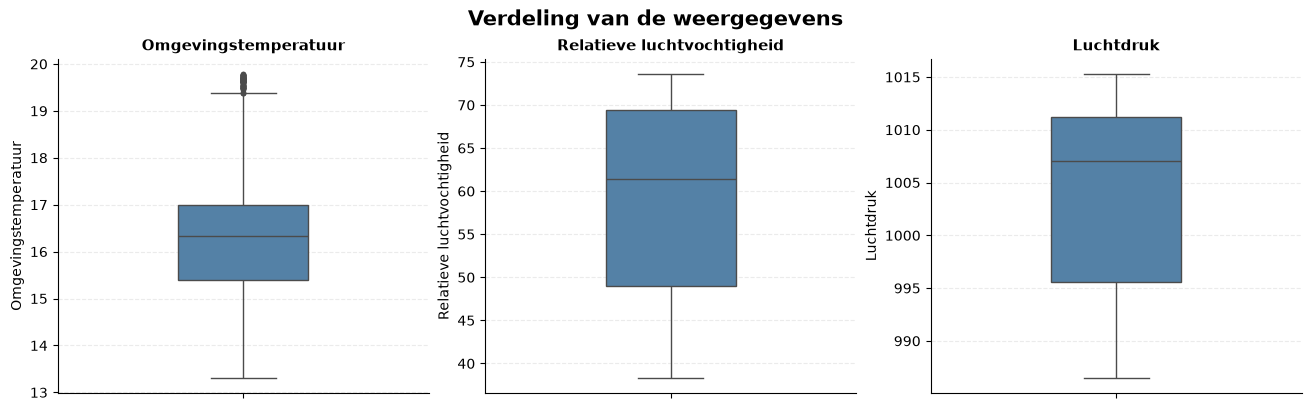

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
    constrained_layout=True
)

for ax, (kolom, naam) in zip(
    axes, weer_variabelen.items()
):
    sns.boxplot(
        y=df_weer[kolom].dropna(),
        ax=ax,
        color="#4682B4",
        width=0.35,
        fliersize=3
    )

    ax.set_title(naam, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(naam)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

fig.suptitle(
    "Verdeling van de weergegevens",
    fontsize=15,
    fontweight="bold"
)

plt.show()


In [8]:

import plotly.graph_objects as go

weer_grafieken = {
    "Temperature-PVMET500": (
        "Omgevingstemperatuur", "Temperatuur (°C)"
    ),
    "Humidity-PVMET500": (
        "Relatieve luchtvochtigheid", "Luchtvochtigheid (%)"
    ),
    "Pressure-PVMET500": (
        "Luchtdruk", "Luchtdruk (eenheid verifiëren)"
    )
}

kleuren = ["#E65100", "#1565C0", "#2E7D32"]

for (kolom, (titel, eenheid)), kleur in zip(
    weer_grafieken.items(), kleuren
):

    data = (
        df_weer[["_time", kolom]]
        .dropna()
        .sort_values("_time")
        .copy()
    )

    # Meetgaten groter dan 20 minuten onderbreken
    verschil = data["_time"].diff().dt.total_seconds() / 60

    x_waarden = []
    y_waarden = []

    for tijd, waarde, minuten in zip(
        data["_time"], data[kolom], verschil
    ):
        if pd.notna(minuten) and minuten > 20:
            x_waarden.append(tijd)
            y_waarden.append(None)

        x_waarden.append(tijd)
        y_waarden.append(float(waarde))

    fig = go.Figure()

    fig.add_trace(
        go.Scatter(
            x=x_waarden,
            y=y_waarden,
            mode="lines+markers",
            name=titel,
            line=dict(color=kleur, width=1.8),
            marker=dict(size=3),
            connectgaps=False,
            hovertemplate=(
                "Tijd: %{x|%d-%m-%Y %H:%M}"
                "<br>Waarde: %{y:.2f}"
                "<extra></extra>"
            )
        )
    )

    fig.update_layout(
        title=dict(text=titel, x=0.5),
        xaxis_title="Datum (UTC)",
        yaxis_title=eenheid,
        height=370,
        template="plotly_white",
        hovermode="closest",
        showlegend=False,
        margin=dict(l=75, r=35, t=65, b=65)
    )

    fig.update_xaxes(tickformat="%d-%m\n%H:%M")

    fig.show()



### 4.4 Analyse van de weergegevens

De weergegevens geven inzicht in de omgevingsomstandigheden tijdens de zonnepaneelmetingen van 23 tot en met 27 oktober 2026.

Voor alle drie de weervariabelen zijn **5.579 metingen** beschikbaar, met een mediaan meetinterval van één minuut. De weergegevens hebben daarmee een hogere tijdsresolutie dan de zonnepaneelmetingen, die iedere tien minuten worden geregistreerd.

### Belangrijkste bevindingen

**1. Omgevingstemperatuur**

De omgevingstemperatuur varieert tussen **13,31 °C en 19,79 °C**, met een gemiddelde van 16,24 °C.

De tijdreeks laat verschillende temperatuurstijgingen en -dalingen zien. Vooral richting 27 oktober stijgt de temperatuur duidelijk.

De omgevingstemperatuur is interessant om te vergelijken met de paneeltemperaturen (`Pt100`). Hiermee kan worden onderzocht hoeveel warmer de zonnepanelen worden dan hun omgeving. Ook kunnen de opvallend negatieve temperatuurmetingen van PV8 hiermee worden vergeleken.

**2. Relatieve luchtvochtigheid**

De relatieve luchtvochtigheid varieert tussen **38,33% en 73,62%**, met een gemiddelde van 59,15%.

De tijdreeks laat relatief grote schommelingen zien, met zowel snelle dalingen als stijgingen.

De luchtvochtigheid kan worden gebruikt om de weersomstandigheden tijdens de zonnepaneelmetingen beter te beschrijven. Ook biedt de dataset mogelijkheden om de relatie tussen omgevingstemperatuur en relatieve luchtvochtigheid te onderzoeken.

**3. Luchtdruk**

De luchtdruk varieert tussen **986,50 en 1015,30**, met een gemiddelde van 1003,73. De meeteenheid moet nog worden bevestigd.

De tijdreeks laat duidelijke veranderingen over meerdere dagen zien, waaronder een sterke stijging richting 26 oktober.

De luchtdruk biedt aanvullende meteorologische context, maar is voor de elektrische prestaties van zonnepanelen minder direct relevant dan temperatuur en zoninstraling.

### Mogelijkheden voor combinatie met zonnepaneeldata

| Combinatie | Mogelijke onderzoekstoepassing |
|---|---|
| Omgevingstemperatuur + `Pt100` | Opwarming en afkoeling van zonnepanelen ten opzichte van de omgeving |
| Omgevingstemperatuur + `voc` | Temperatuurafhankelijkheid van de openklemspanning |
| Luchtvochtigheid + omgevingstemperatuur | Veranderingen in meteorologische omstandigheden |
| Weergegevens + elektrische metingen | Vergelijken van elektrische prestaties onder verschillende weersomstandigheden |

### Samenvatting

De weergegevens vormen een waardevolle aanvulling op de zonnepaneelmetingen. Vooral de **omgevingstemperatuur** biedt interessante mogelijkheden om het thermische gedrag en de elektrische eigenschappen van de zonnepanelen verder te onderzoeken.

De luchtvochtigheid en luchtdruk geven aanvullende informatie over de weersomstandigheden gedurende de meetperiode.

Bij het combineren van beide datasets moet rekening worden gehouden met de verschillende meetfrequenties en de ontbrekende elektrische meetwaarden.



## 5. Beschikbare en ontbrekende variabelen voor diepgaandere analyse

De exploratieve analyses in hoofdstuk 3 en 4 laten zien dat de SolarNL-dataset elektrische en thermische zonnepaneelmetingen, weergegevens en aanvullende sensormetingen bevat.

Deze gegevens bieden verschillende mogelijkheden voor natuurkundig onderzoek. Voor diepgaandere analyses is het belangrijk om onderscheid te maken tussen beschikbare variabelen en aanvullende informatie die nodig is om de waargenomen patronen beter te verklaren.

### 5.1 Beschikbare gegevens en onderzoeksmogelijkheden

**Zonnepaneelmetingen**

Voor de acht zonnepanelen zijn paneeltemperatuur (`Pt100`), fill factor (`ff`), stroom (`impp`, `isc`) en spanning (`vmpp`, `voc`) beschikbaar.

Hiermee kunnen onder andere het maximale elektrische vermogen (`impp × vmpp`), elektrische karakteristieken en temperatuurafhankelijkheid worden onderzocht.

**Weergegevens**

De PVMET500-weersensor registreert omgevingstemperatuur, relatieve luchtvochtigheid en luchtdruk.

Uit hoofdstuk 4 blijkt dat voor iedere weervariabele **5.579 metingen** beschikbaar zijn, met een mediaan meetinterval van één minuut.

Vooral de omgevingstemperatuur is interessant om te combineren met de paneeltemperatuur (`Pt100`). Hiermee kan worden onderzocht hoeveel de zonnepanelen opwarmen ten opzichte van hun omgeving.

De luchtvochtigheid en luchtdruk bieden aanvullende informatie over de meteorologische omstandigheden tijdens de metingen.

**Aanvullende sensormetingen: CMP-10 en Ref**

De zonnepaneeldataset bevat ook de variabelen `CMP-10` en `Ref`.

In hoofdstuk 3 is het tijdsverloop van `CMP-10` gevisualiseerd. De meetreeks laat duidelijke variaties zien, met basiswaarden rond 200–400 en sterke pieken tot ongeveer 1.150 op 24 oktober en boven 1.000 op 26 oktober.

**Vermoedelijk verwijst `CMP-10` naar een pyranometer voor het meten van zoninstraling. Dit is echter nog niet bevestigd.** Ook de relatief hoge basiswaarden tijdens perioden met vermoedelijk weinig zoninstraling maken het belangrijk om de meeteenheid en eventuele kalibratie of omrekening te controleren.

De betekenis van `Ref` is eveneens nog onbekend.

Wanneer wordt bevestigd dat deze variabelen betrouwbare instralingsgegevens bevatten, kunnen ze worden gecombineerd met stroom, spanning en paneeltemperatuur. Daarmee ontstaan mogelijkheden om de invloed van zoninstraling op de elektrische en thermische eigenschappen van zonnepanelen te onderzoeken.

### 5.2 Ontbrekende aanvullende gegevens

Voor een betere natuurkundige interpretatie zijn de volgende gegevens waardevol:

| Aanvullende gegevens | Mogelijke onderzoekstoepassing |
|---|---|
| Betekenis, eenheid en kalibratie van `CMP-10` en `Ref` | Betrouwbare interpretatie van mogelijke instralingsmetingen |
| Windsnelheid en windrichting | Invloed van wind op de koeling van zonnepanelen |
| Bewolking en neerslag | Verklaring van veranderingen in instraling en temperatuur |
| Paneeltype, vermogen en technische specificaties | Vergelijking van gemeten en verwachte prestaties |
| Oriëntatie, hellingshoek en schaduwvorming | Invloed van de fysieke paneelopstelling |
| Temperatuurcoëfficiënten | Relatie tussen temperatuur, spanning en vermogen |
| Sensorposities en kalibratiegegevens | Betrouwbaarheid van temperatuur- en instralingsmetingen |
| Elektrische aansluitingen en meetarchitectuur | Verklaring van identieke elektrische meetwaarden |

Vooral de technische specificaties, de meetopstelling en de documentatie van `CMP-10` zijn belangrijk om de waargenomen verschillen tussen zonnepanelen correct te kunnen interpreteren.

### 5.3 Datakwaliteit en meetregistratie

Uit hoofdstuk 3 blijkt dat de elektrische meetwaarden niet op alle geregistreerde tijdstippen beschikbaar zijn. Vooral bij PV7 en PV8 ontbreken gedurende grote delen van de meetperiode elektrische waarden.

Daarnaast vertonen verschillende zonnepanelen opvallend veel identieke elektrische meetwaarden. Dit kan samenhangen met de manier waarop metingen worden geregistreerd of aan zonnepanelen worden gekoppeld.

Ook de CMP-10-metingen vragen om aanvullende documentatie. De grafiek laat sterke pieken zien, maar zonder bevestiging van de betekenis en meeteenheid kunnen deze nog niet betrouwbaar als veranderingen in zoninstraling worden geïnterpreteerd.

Voor verdere analyse is informatie over de volgende onderdelen waardevol:

- De meetfrequentie en registratie van de verschillende sensoren.
- De synchronisatie tussen weer-, CMP-10- en zonnepaneelmetingen.
- De elektrische meetopstelling en eventuele gedeelde meetkanalen.
- De kalibratie van sensoren en de definitie van de fill factor.
- Eventuele meetstoringen en ontbrekende registraties.

Deze informatie helpt om onderscheid te maken tussen daadwerkelijke fysische verschijnselen en eigenschappen van het meetsysteem.

### 5.4 Mogelijke toepassingen voor natuurkundig onderzoek

Op basis van de beschikbare gegevens zijn verschillende onderzoeksrichtingen interessant:

| Onderzoeksonderwerp | Benodigde variabelen |
|---|---|
| Opwarming van zonnepanelen ten opzichte van de omgeving | `Pt100` + omgevingstemperatuur |
| Temperatuurafhankelijkheid van de openklemspanning | `voc` + `Pt100` |
| Elektrisch vermogen gedurende de dag | `impp` + `vmpp` |
| Relatie tussen zoninstraling en stroomopwekking | `CMP-10` (na verificatie) + `isc` / `impp` |
| Relatie tussen zoninstraling en paneeltemperatuur | `CMP-10` (na verificatie) + `Pt100` |
| Vergelijking van instralingspieken en elektrische stroompieken | `CMP-10` (na verificatie) + `impp` / `isc` |
| Vergelijking van elektrische karakteristieken | `ff`, `impp`, `isc`, `vmpp`, `voc` + paneelspecificaties |
| Betrouwbaarheid en consistentie van sensormetingen | Meetreeksen + kalibratie- en opstellingsgegevens |

### Samenvatting

De SolarNL-dataset biedt mogelijkheden om elektrische, thermische en meteorologische processen rondom zonnepanelen te onderzoeken.

Vooral de combinatie van **paneeltemperatuur, omgevingstemperatuur, stroom en spanning** is interessant. Daarnaast laat de verkenning van `CMP-10` opvallende pieken en variaties zien die mogelijk samenhangen met zoninstraling.

De betekenis en meeteenheid van `CMP-10` moeten echter eerst worden bevestigd voordat deze waarden natuurkundig kunnen worden geïnterpreteerd.

De belangrijkste aanvullende informatie betreft daarom de **technische paneelspecificaties, meetopstelling, sensorregistratie en documentatie van `CMP-10` en `Ref`**.

Met deze informatie kunnen de patronen uit hoofdstuk 3 en 4 beter worden verklaard en kan de dataset gerichter worden ingezet voor toekomstig natuurkundig onderzoek.
